In [1]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
import copy
 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()

In [2]:
def treatState(state,pos_space,vel_space,ang_space,ang_vel_space):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

In [3]:
def findTrainGoal(y,x):# par estimation general
    A=-0.3118 * x**2 + 0.0937 * x +0.1438
    B=71.733 * x**2 - 20.434 * x - 33.804
    C= - 4023.33 * x**2  + 913.21*x + 2104.69 - y
    newGoal= (-B + ( B**2 - 4*A*C)**0.5)/(2*A)
    return int(newGoal)

In [4]:
def findEpsilon(std):
    A=-140.34
    B=140.25
    C=2.97-std
    newepsilon=(-B + ( B**2 - 4*A*C)**0.5)/(2*A)
    return newepsilon

In [5]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.increasing_reward(self.goal - abs(self.goal-result))
        
            
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        

### learner rewards

### Test

In [6]:
def uniTraining(goal,episodeNumber=30000):
    timeSteps=10000
    episodesResults=[]
    episodesTestResults=[]
    episodesTestResultsDeviation=[]
    numberOfTest=50
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)
    qagent=Qlearning(0.1,0.99,0.1,2,goal)

    for episodeIndex in range(episodeNumber):
       
        state,_=env.reset()
        state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
        #print("episode: ",episodeIndex)
        episodeObservation=[]
        for timeIndex in range(timeSteps):
            action=qagent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
            episodeObservation.append([tuple(state),action,tuple(next_state)])
            #qagent.update(tuple(state),action,tuple(next_state),reward)
            state=next_state
            if (terminated):
                #print("Number of steps :",timeIndex)
                
                episodesResults.append(timeIndex)
                break
    
        qagent.episodeRewards(episodeObservation)
        if(episodeIndex %500 ==0):
            qagent.epsilon=0
            testResultList=[]
            for episodeIndex in range(numberOfTest):
        
                state,_=env.reset()
                state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
                for timeIndex in range(timeSteps):
                    action=qagent.getAction(tuple(state))
                    next_state, reward, terminated, truncated, info =env.step(action)
                    next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
                    state=next_state
                    if (terminated):
                        testResultList.append(timeIndex)
                        break
    
            episodesTestResults.append(sum(testResultList)/len(testResultList))
            episodesTestResultsDeviation.append(np.std(episodesTestResults))
            qagent.epsilon=0.1
        
    
    
    env.close() 
    return episodesResults,episodesTestResults,episodesTestResultsDeviation,qagent

In [7]:
def uniTest(agent,epsilon=0):
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)
    timeSteps=10000
    agent.epsilon=epsilon
    last1000testList=[]
    for episodeIndex in range(1000):
    
        state,_=env.reset()
        state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
        for timeIndex in range(timeSteps):
            action=agent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
            state=next_state
            if (terminated):
                last1000testList.append(timeIndex)
                break
    return np.mean(last1000testList),np.std(last1000testList)

In [8]:
def failSafeTrain(qagent,goal):
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)
    timeSteps=10000
    currentmean=uniTest(qagent)[0]
    Failsafe=30
    savedgoal=goal
    currentmin=abs(currentmean -savedgoal)
    currentAgent=copy.deepcopy(qagent)
    while abs(currentmean -savedgoal) > 0.05 * goal and Failsafe>0:
        goal-=int((currentmean -savedgoal)/10)
        qagent.epsilon=0.1
        for episodeIndex in range(1000):
       
            state,_=env.reset()
            state=state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
            episodeObservation=[]
            for timeIndex in range(timeSteps):
                action=qagent.getAction(tuple(state))
                next_state, reward, terminated, truncated, info =env.step(action)
                next_state=state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
                episodeObservation.append([tuple(state),action,tuple(next_state)])
                state=next_state
                if (terminated):
                    
                    break
        
            qagent.episodeRewards(episodeObservation)
        currentmean=uniTest(qagent)[0]
        Failsafe-=1
        if abs(currentmean -savedgoal) < currentmin:
            currentmin=abs(currentmean -savedgoal)
            currentAgent=copy.deepcopy(qagent)
    qagent=currentAgent
    goal=savedgoal
    return qagent,currentmin

In [9]:
goal=130
std=20

e=findEpsilon(std)
goal=findTrainGoal(goal,e)
good=False
while not good:
        episodesResults,episodesTestResults,episodesTestResultsDeviation,agent=uniTraining(goal,episodeNumber=30000)
        agent,testmean=failSafeTrain(agent,goal)
        if testmean  < 0.1 * goal:
            good=True
        else:
            print("repeat",testmean)

118.86233333333334


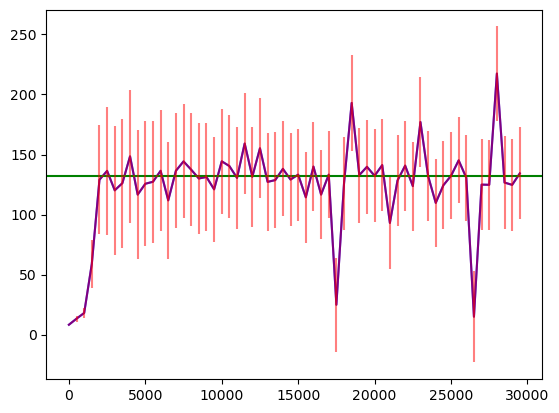

In [10]:
x=[]
for i in range(len(episodesTestResults)):
    x.append(i*500)
plt.plot(x,episodesTestResults,color ='b')
plt.axhline(y= goal,color ='g')
plt.errorbar(x,episodesTestResults,yerr=episodesTestResultsDeviation,color ='r',alpha=0.5)
#plt.savefig("SVG/GoalIncrease1.svg")
print(sum(episodesResults)/len(episodesResults))

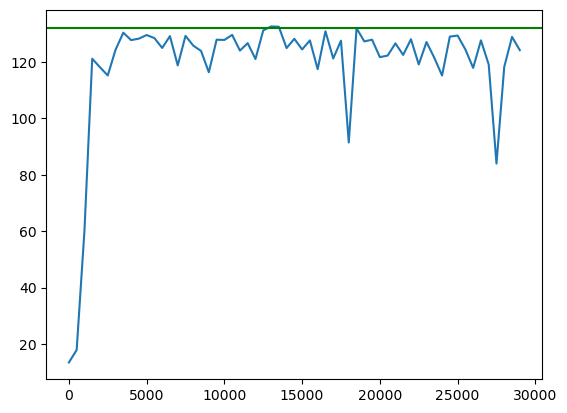

In [11]:
previous100AveragePlot=[]
for i in range(1,len(episodesTestResults)):
    previous100AveragePlot.append(sum(episodesResults[(i*500)-100:(i*500)])/100)
x=[]
for i in range(len(previous100AveragePlot)):
    x.append(i*500)
plt.plot(x,previous100AveragePlot)
plt.axhline(y= goal,color ='g')
#plt.savefig("SVG/GoalIncrease2.svg")

915


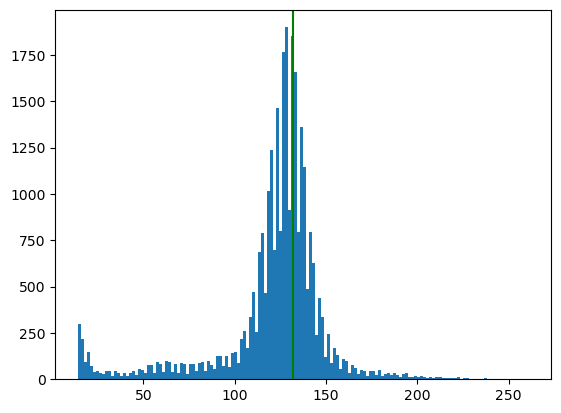

In [12]:
#histogram
episodesResultswithoutOutliers=[]
for i in episodesResults:
    if i >goal * 0.1 and i < goal*2:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers,bins=150)
plt.axvline(x= goal,color ='g')
#plt.savefig("SVG/GoalIncrease3.svg")
print(len(episodesResults)-len(episodesResultswithoutOutliers))

915


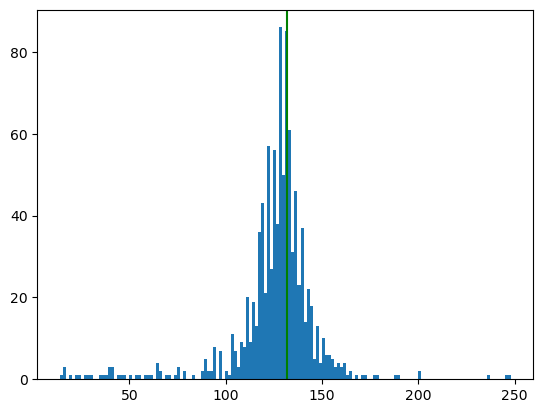

In [13]:
episodesResultswithoutOutliers=[]
for i in episodesResults:
    if i >goal * 0.1 and i < goal*2:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers[-1000:],bins=150)
plt.axvline(x= goal,color ='g')
#plt.savefig("SVG/GoalIncrease4.svg")
print(len(episodesResults)-len(episodesResultswithoutOutliers))

In [14]:
print(np.mean(episodesResults[-1000:]))
print(np.std(episodesResults[-1000:]))

123.766
26.558336619600258


126.719
23.300859190167216


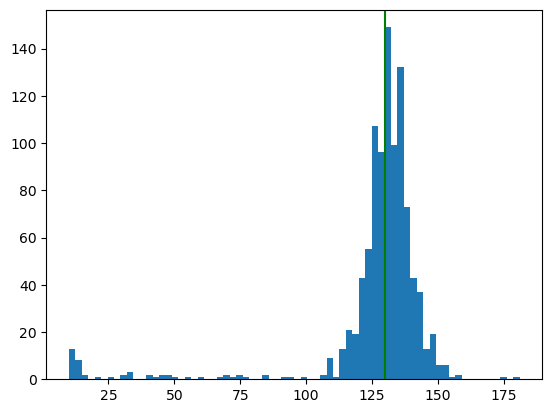

In [15]:
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)
timeSteps=10000
agent.epsilon=e
last1000testList=[]
for episodeIndex in range(1000):
    
    state,_=env.reset()
    state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
    for timeIndex in range(timeSteps):
        action=agent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
        state=next_state
        if (terminated):
            last1000testList.append(timeIndex)
            break



episodesResultswithoutOutliers=[]
for i in last1000testList:
    if i >0 and i < 1000:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers,bins=70)
plt.axvline(x= 130,color ='g')
#plt.savefig("SVG/GoalIncreasedRand150.svg")
print(np.mean(last1000testList))
print(np.std(last1000testList))

In [16]:
# import time
agent.epsilon=0.2
env = gym.make("CartPole-v1", render_mode="human")
for episodeIndex in range(1):

    state,_=env.reset()
    state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
    for timeIndex in range(timeSteps):
        env.render()
        action=agent.getAction(tuple(state))
        
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
        state=next_state
        
        if (terminated):
            print(timeIndex)
            break
        time.sleep(0.02)
env.close()

137
